# Stabilizer 状態 → Graph 状態 + Clifford の導出

`stab_to_graph.py` の使い方デモ。

任意の stabilizer 状態 $|\psi\rangle$ は、あるグラフ $G$ の graph 状態 $|G\rangle$ と局所 Clifford 演算 $C$ を用いて $|\psi\rangle = C|G\rangle$ と表せる (arXiv:2603.17743, Section II)。
ここでは Stim の graph-state 合成機能を使ってこの $(G, C)$ を導出し、得られた回路が元の stabilizer 状態を正しく再現することを検証する。

In [1]:
# ! pip install -r requirements.txt

In [2]:
import sys
sys.path.insert(0, ".")

import networkx as nx
import matplotlib.pyplot as plt

from stab_to_graph import stabilizers_to_graph_state, verify_equivalence, verify_equivalence_qiskit

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/Users/parton/KEIO-UCL/graph_nii/stabilizer_to_graph_state/.venv/lib/python3.9/site-packages/traitlets/traitlets.py", line 651, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/Users/parton/KEIO-UCL/graph_nii/stabilizer_to_graph_state/.venv/lib/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
  File "/Users/parton/KEIO-UCL/graph_nii/stabilizer_to_graph_state/.venv/lib/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/Users/parton/KEIO-UCL/graph_nii/stabilizer_to_graph_state/.venv/lib/python3.9/site-packages/traitlets/traitlets.py", line 706, in __get__
    return self.get(obj, cls)  # type:ignore[return-value]
  File "/Users/parto

## 例1: 5量子ビット符号 $[\![5,1,3]\!]$ の $|0\rangle_L$

In [3]:
stabilizers_5q = ["XZZXI", "IXZZX", "XIXZZ", "ZXIXZ", "ZZZZZ"]

decomp = stabilizers_to_graph_state(stabilizers_5q)
print("Graph edges:", sorted(decomp.graph.edges()))
print("\nLocal Clifford circuit C:")
print(decomp.local_clifford_circuit)
print("\nFull preparation circuit:")
print(decomp.preparation_circuit)

print("\nEquivalence check (Stim):", verify_equivalence(stabilizers_5q, decomp.preparation_circuit))
print("Equivalence check (Qiskit):", verify_equivalence_qiskit(stabilizers_5q, decomp.preparation_circuit))

Graph edges: [(0, 2), (0, 3), (0, 4), (1, 2), (1, 4), (2, 3), (2, 4)]

Local Clifford circuit C:
X 2
Z 0 4
H 2

Full preparation circuit:
RX 0 1 2 3 4
TICK
CZ 0 2 0 3 0 4 1 2 1 4 2 3 2 4
TICK
X 2
Z 0 4
H 2

Equivalence check (Stim): True
Equivalence check (Qiskit): True


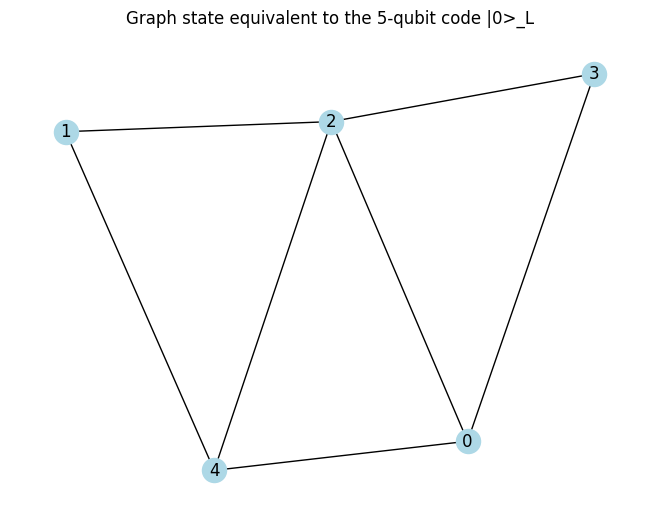

In [4]:
nx.draw(decomp.graph, with_labels=True, node_color="lightblue")
plt.title("Graph state equivalent to the 5-qubit code |0>_L")
plt.show()

## 例2: Steane 符号 $[\![7,1,3]\!]$ の $|0\rangle_L$

In [5]:
steane_x = ["IIIXXXX", "IXXIIXX", "XIXIXIX"]
steane_z = ["IIIZZZZ", "IZZIIZZ", "ZIZIZIZ"]
logical_z = "ZZZZZZZ"
stabilizers_7q = steane_x + steane_z + [logical_z]

decomp7 = stabilizers_to_graph_state(stabilizers_7q)
print("Graph edges:", sorted(decomp7.graph.edges()))
print("Equivalence check (Stim):", verify_equivalence(stabilizers_7q, decomp7.preparation_circuit))
print("Equivalence check (Qiskit):", verify_equivalence_qiskit(stabilizers_7q, decomp7.preparation_circuit))

Graph edges: [(0, 1), (0, 2), (1, 4), (1, 5), (2, 4), (2, 6), (3, 4), (3, 5), (3, 6)]
Equivalence check (Stim): True
Equivalence check (Qiskit): True


## Qiskit によるクロスチェック

上記の等価性検証は Stim (`peek_observable_expectation`) だけに依存している。実装のバグが Stim 側のバグに起因する可能性を排除するため、独立したライブラリである Qiskit (`qiskit.quantum_info.StabilizerState`) でも同じ検証を行う (`verify_equivalence_qiskit`)。

注意点として、Pauli 文字列の量子ビット順序規約が Stim (左端が qubit 0) と Qiskit (little-endian、右端が qubit 0) で逆になる。非対称なランダム stabilizer 状態で試すと、この反転を行わない場合に検証が失敗することが確認できる。

In [6]:
import stim

# 非対称なランダム stabilizer 状態でも一致することを確認
for n in [1, 2, 3, 6, 10]:
    t = stim.Tableau.random(n)
    stabs = t.to_stabilizers()
    d = stabilizers_to_graph_state(stabs)
    print(f"n={n}: graph edges={sorted(d.graph.edges())}")
    ok_stim = verify_equivalence(stabs, d.preparation_circuit)
    ok_qiskit = verify_equivalence_qiskit(stabs, d.preparation_circuit)
    print(f"n={n}: stim={ok_stim} qiskit={ok_qiskit}")

n=1: graph edges=[]
n=1: stim=True qiskit=True
n=2: graph edges=[(0, 1)]
n=2: stim=True qiskit=True
n=3: graph edges=[]
n=3: stim=True qiskit=True
n=6: graph edges=[(0, 3), (2, 4)]
n=6: stim=True qiskit=True
n=10: graph edges=[(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 8), (1, 3), (1, 7), (2, 4), (2, 6), (2, 7), (3, 4), (3, 6), (3, 9), (4, 6), (4, 7), (4, 8), (5, 6), (5, 7), (6, 7), (7, 8), (7, 9)]
n=10: stim=True qiskit=True


# 論文Table II に出てくる符号のグラフ状態導出

`qec_codes.py` に、論文 Table I の符号のうち出典を確認できたもの (8/14) を [MQT QECC](https://github.com/munich-quantum-toolkit/qecc) 経由でまとめてある。残り6つ ([[36,8,6]], [[40,20,6]] (non-CSS), [[42,12,5]], [[48,6,8]], [[64,12,8]], [[80,8,10]]) は論文中に引用がなく、厳密な check 行列の出典を確認できなかったため未対応 (詳細は README 参照)。

In [7]:
from qec_codes import CODES, UNAVAILABLE_TABLE_ROWS, get_stabilizers

print("対応済み:", list(CODES.keys()))
print("未対応:", UNAVAILABLE_TABLE_ROWS)

対応済み: ['surface_9_1_3', 'carbon_12_2_4', 'reed_muller_15_1_3', 'hamming_15_7_3', 'color_17_1_5', 'color_19_1_5', 'golay_23_1_7', 'gross_144_12_12']
未対応: ['[[36,8,6]]', '[[40,20,6]] (non-CSS)', '[[42,12,5]]', '[[48,6,8]]', '[[64,12,8]]', '[[80,8,10]]']


In [8]:
for key, meta in CODES.items():
    stabilizers = get_stabilizers(key)
    decomp = stabilizers_to_graph_state(stabilizers)
    ok_stim = verify_equivalence(stabilizers, decomp.preparation_circuit)
    ok_qiskit = verify_equivalence_qiskit(stabilizers, decomp.preparation_circuit)
    print(
        f"{meta['table_row']:14s} {meta['name']:35s} n={meta['n']:>4} "
        f"edges={decomp.graph.number_of_edges():>4} stim_ok={ok_stim} qiskit_ok={ok_qiskit}"
    )

[[9,1,3]]      Surface code                        n=   9 edges=  10 stim_ok=True qiskit_ok=True
[[12,2,4]]     Carbon code                         n=  12 edges=  27 stim_ok=True qiskit_ok=True
[[15,1,3]]     Reed-Muller code                    n=  15 edges=  31 stim_ok=True qiskit_ok=True
[[15,7,3]]     Hamming code                        n=  15 edges=  49 stim_ok=True qiskit_ok=True
[[17,1,5]]     Color code (4.8.8, square-octagon)  n=  17 edges=  39 stim_ok=True qiskit_ok=True
[[19,1,5]]     Color code (hexagonal)              n=  19 edges=  51 stim_ok=True qiskit_ok=True
[[23,1,7]]     Golay code                          n=  23 edges=  77 stim_ok=True qiskit_ok=True
[[144,12,12]]  Gross code                          n= 144 edges=3142 stim_ok=True qiskit_ok=True


### Golay 符号 $[\![23,1,7]\!]$ のグラフを可視化

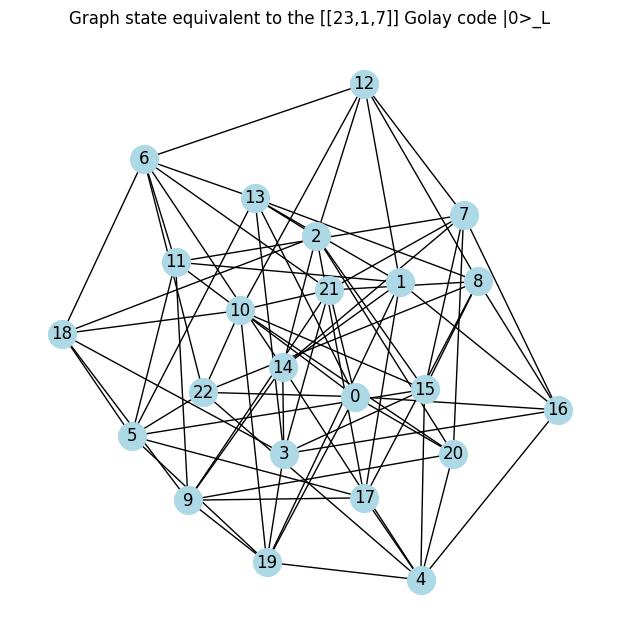

In [9]:
golay_stabilizers = get_stabilizers("golay_23_1_7")
golay_decomp = stabilizers_to_graph_state(golay_stabilizers)

plt.figure(figsize=(6, 6))
nx.draw(golay_decomp.graph, with_labels=True, node_color="lightblue", node_size=400)
plt.title("Graph state equivalent to the [[23,1,7]] Golay code |0>_L")
plt.show()